In [1]:
import os
import pickle

import numpy as np
import pandas as pd
from ultralytics import YOLO
import tqdm
import matplotlib.pyplot as plt

%matplotlib inline

In [2]:
base_pth = "results"
model_names = [
    "merged_furniture",
    "merged_furniture_no_occupied",
    "merged_furniture_no_occupied_chairs"
]

model_names_v2 = [
    "v2_batch6_merged_furniture",
    # "v2_batch6_merged_furniture_4_classes",
    # "v2_batch6_merged_furniture_no_occupied_chairs",
    # "v2_batch6_merged_furniture_no_occupied_chairs_4_classes",
    # "v2_batch6_merged_furniture_chair_occupied",
    # "v2_batch6_merged_furniture_chair_occupied_5_classes",
    "v2_batch6_merged_furniture_table_chair",
    "v2_batch6_merged_furniture_table_chair_chair_occupied",
]

thres = np.arange(0.2, 0.61, 0.05)

In [3]:
thres = np.arange(0.2, 0.61, 0.05)

results = {}
for model_name in model_names_v2:
    model = YOLO(os.path.join(base_pth, model_name, "weights/best.pt"))
    
    box_mrs = []
    box_mps = []
    box_fs = []

    pose_mrs = []
    pose_mps = []
    pose_fs = []

    for th in tqdm.tqdm(thres):
        metrics = model.val(
            task="pose", iou=0.5, conf=th, device=[0, 1, 2], batch=30, classes=np.arange(2), verbose=False)
        box_mrs.append(metrics.box.r)
        box_mps.append(metrics.box.p)
        box_fs.append(metrics.box.f1)

        pose_mrs.append(metrics.pose.r)
        pose_mps.append(metrics.pose.p)
        pose_fs.append(metrics.pose.f1)
    
    results[model_name] = {
        "box_mr": box_mrs,
        "box_mp": box_mps,
        "box_f1": box_fs,
        "pose_mr": pose_mrs,
        "pose_mp": pose_mps,
        "pose_f1": pose_fs
    }

with open("val_results_v3.pkl", "wb") as f:
    pickle.dump(results, f)

  0%|          | 0/9 [00:00<?, ?it/s]

Ultralytics YOLOv8.2.31 🚀 Python-3.10.13 torch-2.3.1+cu121 CUDA:0 (NVIDIA GeForce GTX 980 Ti, 6078MiB)
                                                            CUDA:1 (NVIDIA GeForce GTX 980 Ti, 6078MiB)
                                                            CUDA:2 (NVIDIA GeForce GTX 980 Ti, 6075MiB)
YOLOv8n-pose summary (fused): 187 layers, 3078635 parameters, 0 gradients, 8.3 GFLOPs


val: Scanning /home/klymy/projects/researches/object-detection-v3/datasets/v2_batch6/merged_furniture/labels/val.cache... 292 images, 0 backgrounds, 0 corrupt: 100%|██████████| 292/292 [00:00<?, ?it/s]


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Pose(P          R      mAP50  mAP50-95): 100%|██████████| 10/10 [00:11<00:00,  1.12s/it]


                   all        292       3858      0.816      0.621      0.749       0.43      0.843      0.748      0.835      0.825
Speed: 1.2ms preprocess, 2.8ms inference, 0.0ms loss, 3.6ms postprocess per image
Results saved to /home/klymy/.pyenv/runs/pose/val298


...

 89%|████████▉ | 8/9 [04:53<00:40, 40.26s/it]

Ultralytics YOLOv8.2.31 🚀 Python-3.10.13 torch-2.3.1+cu121 CUDA:0 (NVIDIA GeForce GTX 980 Ti, 6078MiB)
                                                            CUDA:1 (NVIDIA GeForce GTX 980 Ti, 6078MiB)
                                                            CUDA:2 (NVIDIA GeForce GTX 980 Ti, 6075MiB)


val: Scanning /home/klymy/projects/researches/object-detection-v3/datasets/v2_batch6/merged_furniture_table_chair_chair_occupied/labels/val.cache... 292 images, 5 backgrounds, 0 corrupt: 100%|██████████| 292/292 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Pose(P          R      mAP50  mAP50-95): 100%|██████████| 10/10 [00:07<00:00,  1.37it/s]


                   all        292       2922      0.838      0.474       0.66      0.391       0.91      0.515      0.718      0.709
Speed: 1.1ms preprocess, 3.4ms inference, 0.0ms loss, 3.4ms postprocess per image
Results saved to /home/klymy/.pyenv/runs/pose/val324


100%|██████████| 9/9 [05:04<00:00, 33.86s/it]


In [4]:
with open("val_results_v3.pkl", "rb") as f:
    results = pickle.load(f)

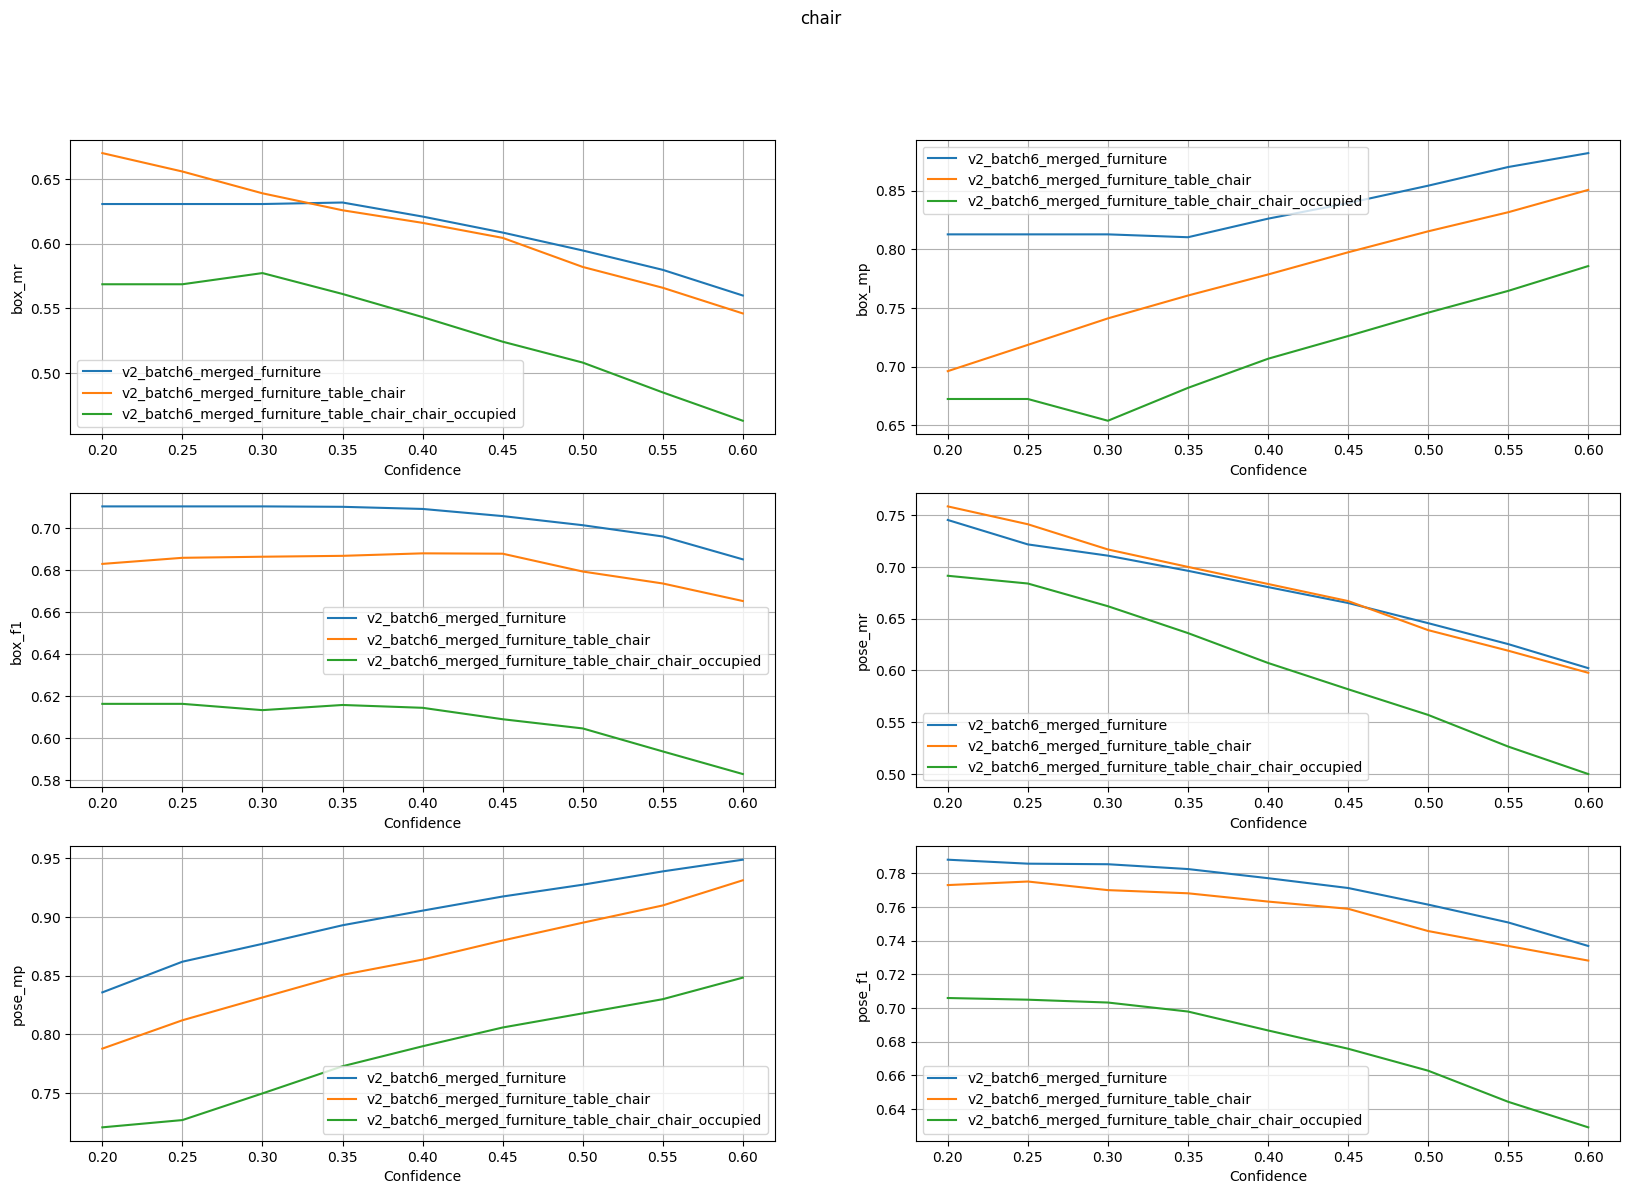

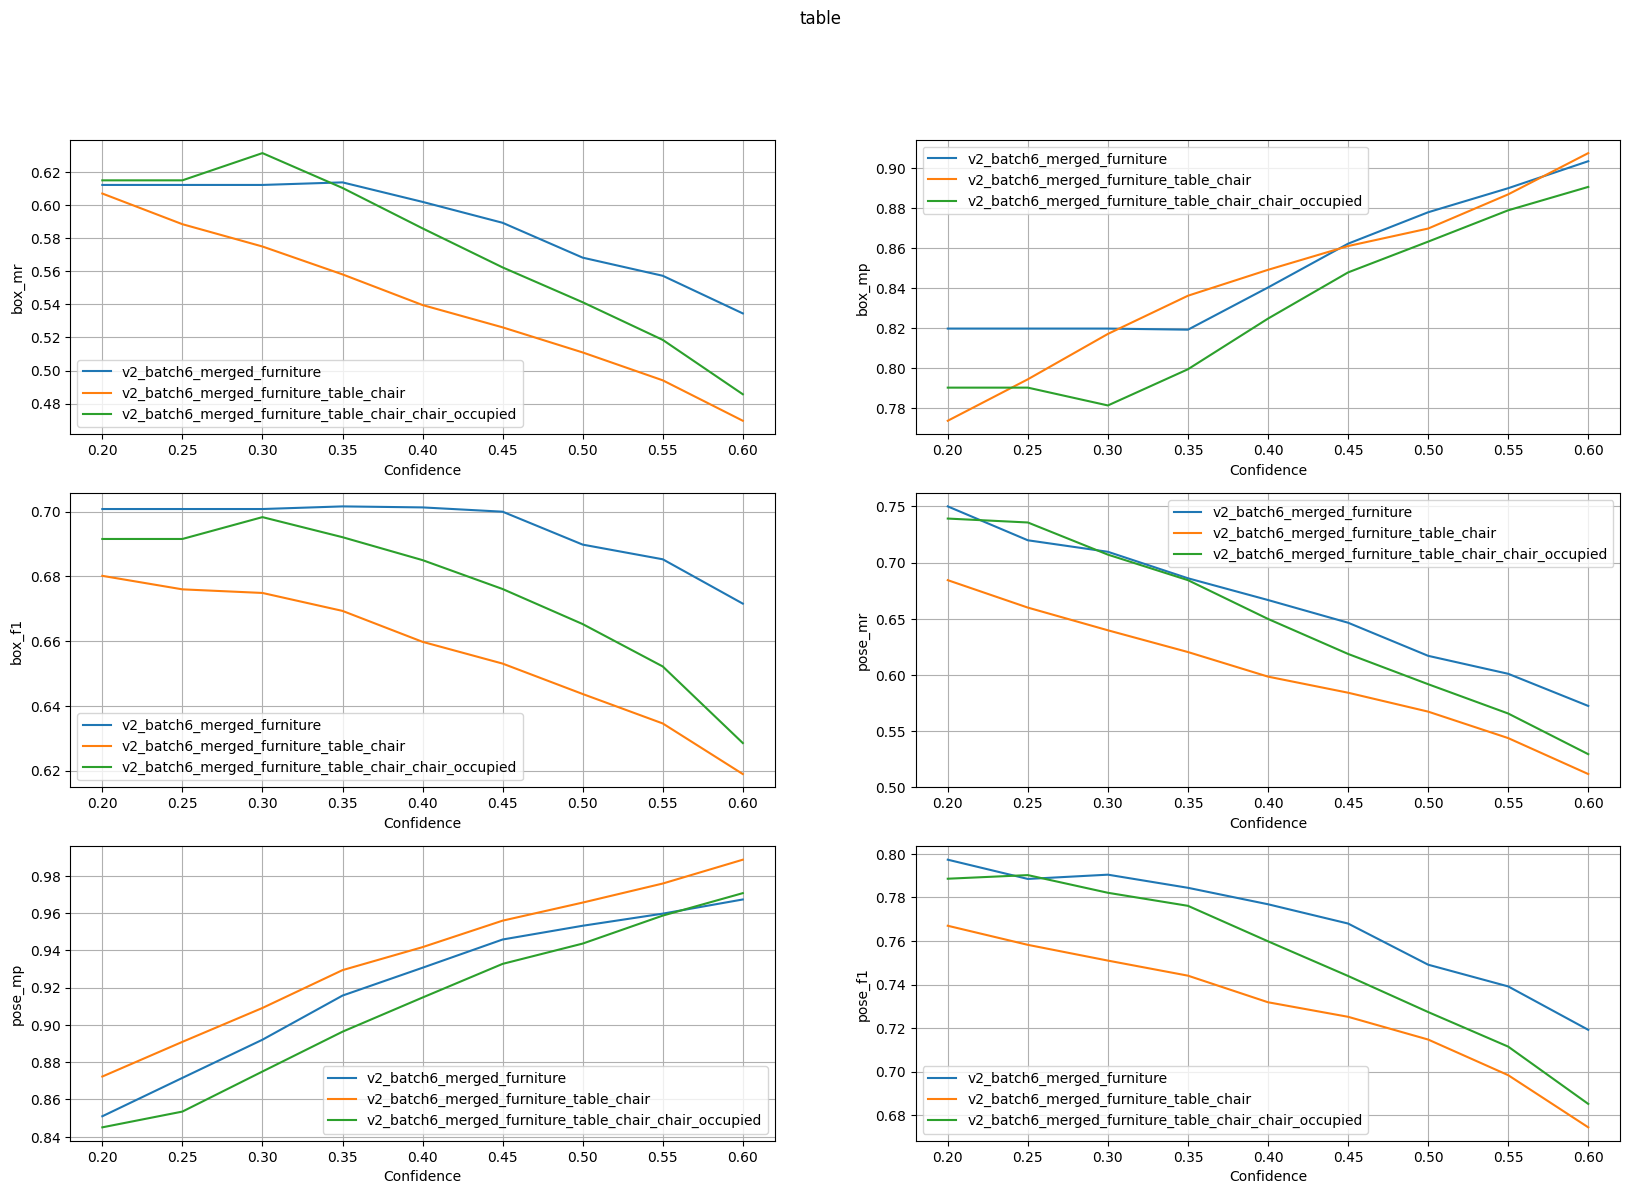

In [14]:
class_names = ["chair", "table"]
for class_idx in range(2):
    plt.figure(figsize=(20, 13))

    plt.suptitle(class_names[class_idx])
    for model_name, model_results in results.items():
        for idx, (metric_name, metric_values) in enumerate(model_results.items()):
            plt.subplot(3, 2, 1 + idx)
            plt.plot(thres, np.stack(metric_values)[:, class_idx], label=model_name)
            plt.grid()
            plt.legend()
            plt.ylabel(metric_name)
            plt.xlabel("Confidence")


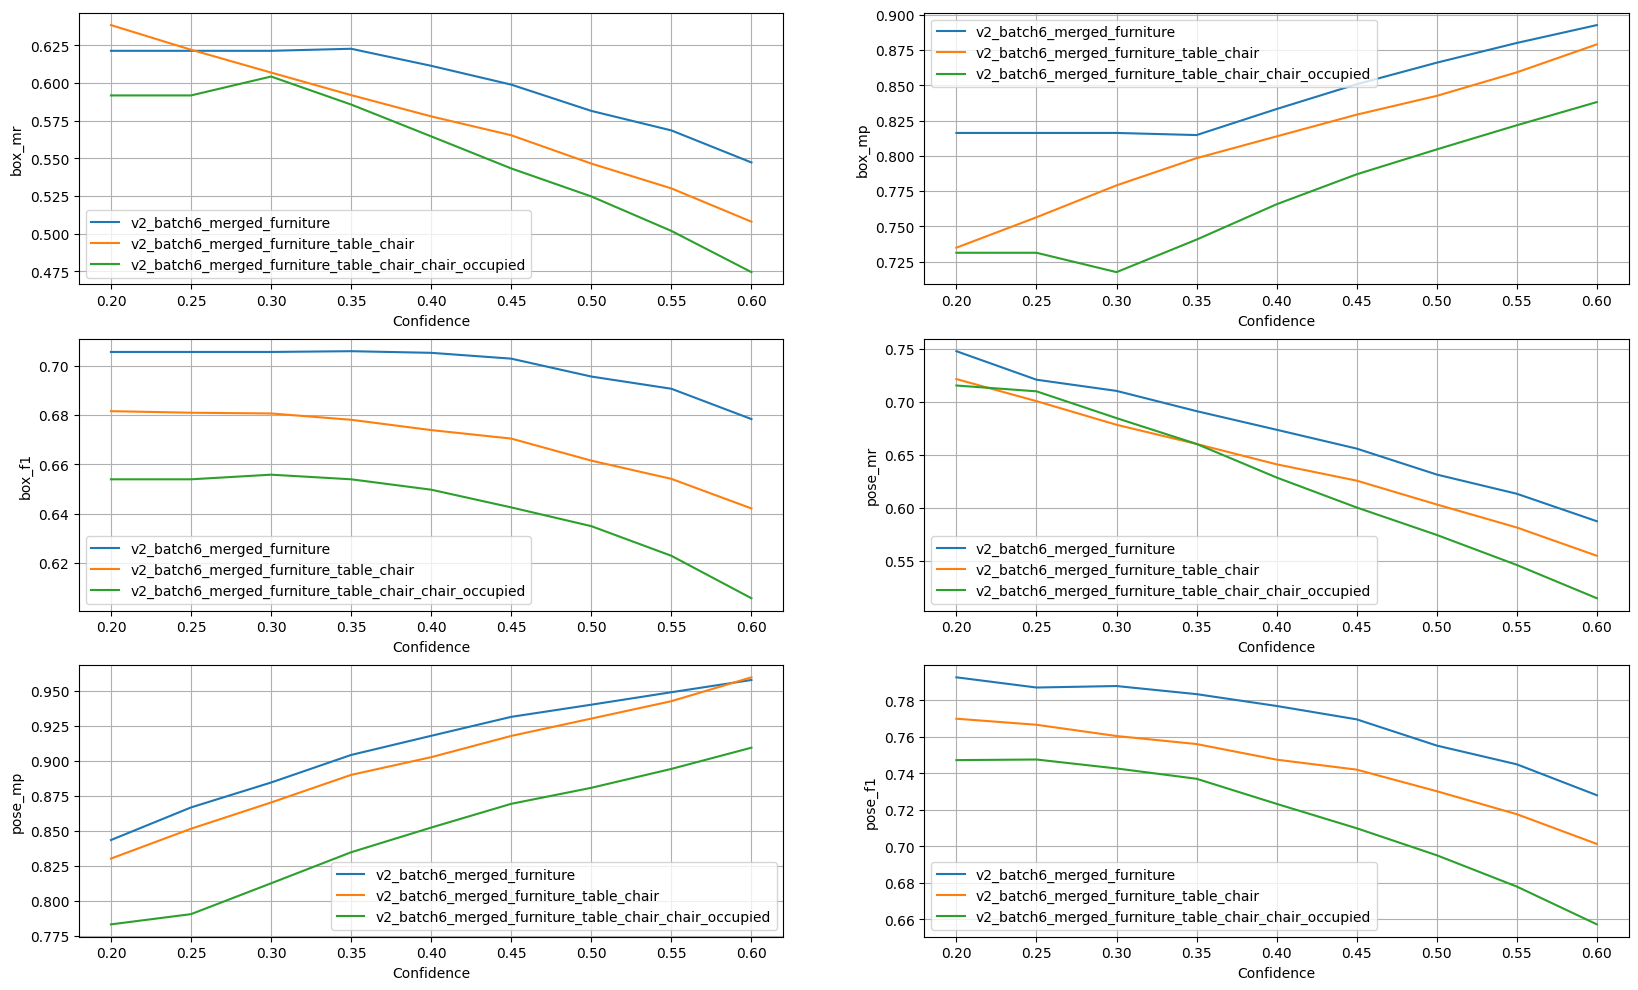

In [15]:

plt.figure(figsize=(20, 12))

for model_name, model_results in results.items():
    for idx, (metric_name, metric_values) in enumerate(model_results.items()):
        plt.subplot(3, 2, 1 + idx)
        plt.plot(thres, np.stack(metric_values).mean(axis=1), label=model_name)
        plt.grid()
        plt.legend()
        plt.ylabel(metric_name)
        plt.xlabel("Confidence")


In [16]:
thres_idx = np.where(thres == 0.35)[0][0] + 1
thres_idx

4

In [18]:
results_avg = {}
for model_name, model_results in results.items():
    results_avg[model_name] = {}
    for metric_name, metric_values in model_results.items():
        results_avg[model_name][metric_name] = np.mean(metric_values[thres_idx])


pd.DataFrame(results_avg).T

,box_mr,box_mp,box_f1,pose_mr,pose_mp,pose_f1
v2_batch6_merged_furniture,0.611413,0.833148,0.705163,0.673596,0.918001,0.776923
v2_batch6_merged_furniture_table_chair,0.577834,0.813760,0.673829,0.641003,0.902711,0.747489
v2_batch6_merged_furniture_table_chair_chair_occupied,0.564556,0.765661,0.649660,0.628549,0.852320,0.723254


In [19]:
results_chair = {}
for model_name, model_results in results.items():
    results_chair[model_name] = {}
    for metric_name, metric_values in model_results.items():
        results_chair[model_name][metric_name] = metric_values[thres_idx][0]


pd.DataFrame(results_chair).T

,box_mr,box_mp,box_f1,pose_mr,pose_mp,pose_f1
v2_batch6_merged_furniture,0.620974,0.826109,0.709001,0.680524,0.905331,0.776994
v2_batch6_merged_furniture_table_chair,0.616105,0.778514,0.687853,0.683521,0.863701,0.763119
v2_batch6_merged_furniture_table_chair_chair_occupied,0.543253,0.706677,0.614281,0.607266,0.789947,0.686664


In [20]:
results_table = {}
for model_name, model_results in results.items():
    results_table[model_name] = {}
    for metric_name, metric_values in model_results.items():
        results_table[model_name][metric_name] = metric_values[thres_idx][1]


pd.DataFrame(results_table).T

,box_mr,box_mp,box_f1,pose_mr,pose_mp,pose_f1
v2_batch6_merged_furniture,0.601852,0.840188,0.701324,0.666667,0.930670,0.776851
v2_batch6_merged_furniture_table_chair,0.539562,0.849007,0.659804,0.598485,0.941722,0.731858
v2_batch6_merged_furniture_table_chair_chair_occupied,0.585859,0.824645,0.685039,0.649832,0.914692,0.759843


In [4]:
model = YOLO(os.path.join(base_pth, "v2_batch6_merged_furniture", "weights/best.pt"))
model.names

{0: 'chair',
 1: 'table',
 2: 'laptop_opened',
 3: 'monitor',
 4: 'keyboard',
 5: 'plants',
 6: 'cabinet'}

In [17]:
_ = model.val(task="pose", iou=0.5, conf=0.3, device=[0, 1, 2], batch=30)

Ultralytics YOLOv8.2.31 🚀 Python-3.10.13 torch-2.3.1+cu121 CUDA:0 (NVIDIA GeForce GTX 980 Ti, 6078MiB)
                                                            CUDA:1 (NVIDIA GeForce GTX 980 Ti, 6078MiB)
                                                            CUDA:2 (NVIDIA GeForce GTX 980 Ti, 6075MiB)


val: Scanning /home/klymy/projects/researches/object-detection-v3/datasets/v2_batch6/merged_furniture/labels/val.cache... 292 images, 0 backgrounds, 0 corrupt: 100%|██████████| 292/292 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Pose(P          R      mAP50  mAP50-95): 100%|██████████| 10/10 [00:12<00:00,  1.28s/it]


                   all        292       6055      0.636      0.441      0.552      0.321      0.721        0.5      0.627      0.616
                 chair        285       2670      0.793      0.643      0.749      0.422      0.877      0.711       0.82      0.811
                 table        284       1188       0.79      0.629      0.744      0.446      0.892       0.71      0.828      0.819
         laptop_opened        207        664      0.576      0.483      0.548      0.292       0.67      0.562      0.639      0.617
               monitor        167        553       0.55      0.349      0.471      0.275       0.65      0.412      0.556       0.54
              keyboard         97        299      0.583      0.271      0.437      0.259      0.662      0.308      0.492      0.485
                plants        164        313      0.569      0.342      0.445       0.26      0.676      0.406      0.549      0.543
               cabinet        217        368       0.59      0.367   

In [18]:
_.box.f1, _.pose.f1

(array([    0.70997,     0.70042,      0.5258,     0.42699,     0.36986,     0.42715,     0.45226]),
 array([    0.78527,     0.79044,     0.61097,     0.50442,     0.42009,     0.50699,     0.47906]))

In [19]:
_.box.f1.mean(), _.pose.f1.mean()

(0.5160646692086932, 0.5853208173085483)